# HLLC experiments with entropy (fix)

### Setup

In [1]:
import matplotlib.pyplot as pl
import numpy as np
import time

## Total energy based solver

### HLLC

In [2]:
def hllc(lr,gamma=1.4,verbose=0,diag=None):
    qleft,qright=lr
    
    if gamma==1:
        g1=1.
    else:
        g1=1./(gamma-1.0)
    i,n=qleft.shape
    flux=np.zeros((5,n))
    
    if type(diag) is dict:
        diag['case']=[]
        diag['SL']=[]
        diag['SR']=[]
        diag['ro']=[]
        diag['uo']=[]
        diag['Po']=[]
        diag['eo']=[]

    for i in range(n):
        # Left variables
        rl=qleft[0,i]
        Pl=qleft[1,i]
        ul=qleft[2,i]
        el = Pl*g1+0.5*ul**2*rl

        # Right variables
        rr=qright[0,i]
        Pr=qright[1,i]
        ur=qright[2,i]
        er = Pr*g1+0.5*ur**2*rr

        # Find the largest eigenvalues in the normal direction to the interface
        cfastl = (gamma*Pl/rl)**0.5
        cfastr = (gamma*Pr/rr)**0.5

        # HLL wave speed
        SL=min(ul,ur)-max(cfastl,cfastr)
        SR=max(ul,ur)+max(cfastl,cfastr)

        # Sample the solution at x/t=0
        if SL > 0.0:       # supersonic positive speed
            icase=1
            ro=rl
            uo=ul
            Po=Pl
            eo=el
        elif SR < 0.0:     # supersonic negative speed
            icase=4
            ro=rr
            uo=ur
            Po=Pr
            eo=er
        else:
            # Lagrangian sound speed
            rcl=rl*(ul-SL)
            rcr=rr*(SR-ur)

            # Acoustic star state
            uo=(rcr*ur   +rcl*ul   +  (Pl-Pr))/(rcr+rcl)
            Po=(rcr*Pl+rcl*Pr+rcl*rcr*(ul-ur))/(rcr+rcl)

            # Left / right star region variables
            if uo > 0.0:        # positive momentum transport
                icase=2
                ro=rl*(SL-ul)/(SL-uo)
                eo=((SL-ul)*el-Pl*ul+Po*uo)/(SL-uo)
            else:               # negative momentum transport
                icase=3
                ro=rr*(SR-ur)/(SR-uo)
                eo=((SR-ur)*er-Pr*ur+Po*uo)/(SR-uo)

        if verbose:
            pbzrint(('{:4d}{:3d}'+8*'{:8.3f}').format(i,icase,SL,SR,SAL,SAR,ro,uo,Po,eo))

        if type(diag) is dict:
            diag['case'].append(icase)
            diag['SL'].append(SL)
            diag['SR'].append(SR)
            diag['ro'].append(ro)
            diag['uo'].append(uo)
            diag['Po'].append(Po)
            diag['eo'].append(eo)

        so = ro*np.log(Po/ro**gamma)/(gamma-1)
        flux[0,i] = ro*uo
        flux[1,i] = (eo+Po)*uo
        flux[2,i] = ro*uo*uo+Po
        flux[3,i] = 0.5*ro*uo*uo**2
        flux[4,i] = so*uo

    return flux

n=5000
left=np.ones((5,n))
rght=np.ones((5,n))

start=time.time()
flux=hllc((left,rght))
print('{:.1f} microsec/cell'.format(1e6*(time.time()-start)/n))

11.0 microsec/cell


### Slope limiter (MonCen)

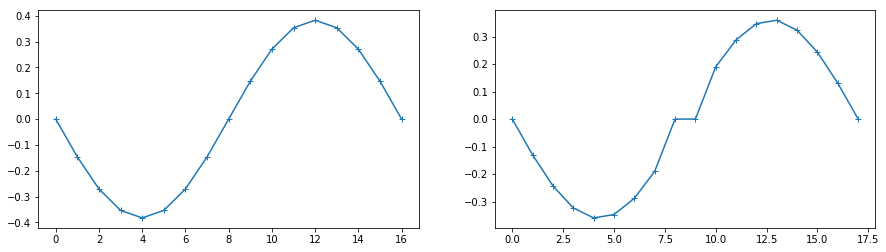

In [3]:
def moncen(q):
    n=len(q)
    df=np.zeros(n)

    for i in range(1,n-1):
        dl = q[i  ] - q[i-1]
        dr = q[i+1] - q[i  ]
        dc = 0.5*(dl+dr)
        sl = 2*min(abs(dl),abs(dr)) if dl*dr > 0 else 0.0
        df[i] = np.sign(dc)*min(sl,abs(dc))

    df[0]=0.0
    df[-1]=0.0
    return df

def slope(q,method='moncen'):
    if method=='moncen':
        return moncen(q)

def slopes(f,method='moncen'):
    df=np.zeros(f.shape)
    for i,v in enumerate(f):
        df[i]=slope(v,method=method)
    return df

pl.figure(figsize=(15,4))
pl.subplot(1,2,1); n=16; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');
pl.subplot(1,2,2); n=17; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');

## Initial conditions

### Stationary shock

The Rankine-Hugoniot relations are
$$
\frac{\rho_2}{\rho_1} = \frac{(\gamma+1){\scr M}^2}{(\gamma-1){\scr M}^2+2} 
$$

$$
\frac{P_2}{P_1} = 1+\frac{2\gamma}{\gamma+1} ({\scr M}^2-1)
$$

where, wirth $c_1$ the upstream sound speed:
$$
u_1 = {\scr M} c_1
$$

Since entropy $S$ per unit mass is
$$
S = \frac{\ln(P/\rho^\gamma)}{\gamma-1}
$$
the jump in $S$ is
$$
S_2 - S_1 = \frac{1}{\gamma-1}\left\{\ln(P_2/P_1)-\gamma\ln(\rho_2/\rho_1)\right\}
$$

#### Implementation

In [4]:
def stationary_shock(n=64,rl=1.0,cs=1.0,mach=2,gamma=1.4,m=None):
    r=(gamma+1)*mach**2/((gamma-1)*mach**2+2)
    p=1+(2*gamma)/(gamma+1)*(mach**2-1)
    rr=r*rl
    ul=mach*cs
    ur=ul/r
    pl=rl*cs**2/gamma
    pr=pl*p
    el=0.5*rl*ul**2+pl/(gamma-1)
    er=0.5*rr*ur**2+pr/(gamma-1)
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((5,n))
    f[0,0:m]=rl
    f[0,m:n]=rr
    f[1,0:m]=el
    f[1,m:n]=er
    f[2,0:m]=rl*ul
    f[2,m:n]=rr*ur
    f[3,0:m]=0.5*rl*ul**2
    f[3,m:n]=0.5*rr*ur**2
    f[4,0:m]=rl*np.log(pl/rl**gamma)/(gamma-1)
    f[4,m:n]=rr*np.log(pr/rr**gamma)/(gamma-1)
    f[:,m-1]=0.9*f[:,m-2]+0.1*f[:,m+2]
    f[:,m  ]=0.5*f[:,m-2]+0.5*f[:,m+2]
    f[:,m+1]=0.1*f[:,m-2]+0.9*f[:,m+2]
    return x,f

### IC chooser

In [5]:
def IC(case='stationary_shock',**kwarg):
    if case=='stationary_shock':
        return stationary_shock(**kwarg)

### Primitive variables
This version also returns kinetic energy

In [50]:
labels=['d','P','u','K','s']
def ctoprim(f,gamma=1.4):
    """ This version uses f[0:3]as input, sets f[3:5] and return a set of
        primitive variables
    """
    m,n=f.shape
    d=f[0]
    E=f[1]
    p=f[2]
    u=p/d
    K=0.5*d*u**2
    P=(gamma-1)*(E-K)
    s=np.log(P/d**gamma)/(gamma-1)
    S=s*d
    f[3]=K
    f[4]=S
    return np.array((d,P,u,K,s))

### Predictor

In [7]:
def predict(f,dt=0,gamma=1.4):
    left=[]
    rght=[]
    for v in f:
        dv=slope(v)
        left.append(v+0.5*dv)
        rght.append(v-0.5*dv)
    d=f[0]
    p=f[1]
    u=f[2]
    s=f[3]
    dddx=dv[0]
    dpdx=dv[1]
    dudx=dv[2]
    dsdx=dv[3]
    dddt=-u*dddx-d*dudx                   # continuity
    dudt=-u*dudx-dpdx/d                   # eqn of motion
    dsdt=-u*dsdx                          # constant entropy
    dpdt=-u*dpdx-p*dudx*(gamma-1)         # adiabatic pressure evolution
    df=np.array([dddt,dudt,dsdt,dpdt,dsdt])*dt # predicted update
    left+=df                              # apply to left
    rght+=df                              # apply to rght
    left=np.roll(left,1,axis=1)
    left[:,0]=left[:,1]
    return np.array(left),np.array(rght)

Test

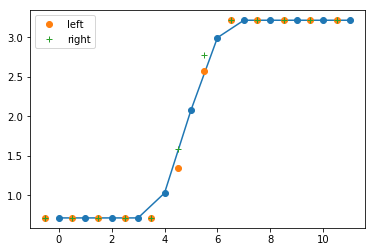

In [8]:
n=12
x,f=IC(n=n,m=5)
x=np.arange(n)
p=ctoprim(f)
l,r=predict(p)
pl.plot(x,p[1],'-o')
pl.plot(x-0.5,l[1],'o',label='left')
pl.plot(x-0.5,r[1],'+',label='right')
pl.legend();

### Flux

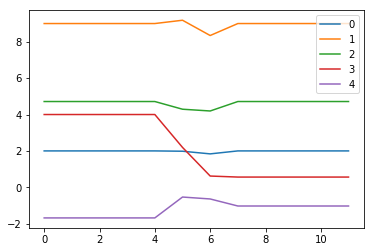

In [9]:
flux=hllc((l,r))
for i,v in enumerate(flux):
    pl.plot(v,label=i)
pl.legend();

### Boundary conditions

In [10]:
def BCs(df):
    df[:,0]=0.0
    df[:,-1]=0.0
    return df

### Flux divergence

In [11]:
def div(flux):
    df=np.roll(flux,-1,axis=1)-flux
    df[:,0]=0.0
    return df

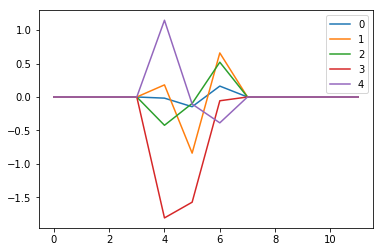

In [12]:
df=BCs(div(flux))
for i,v in enumerate(df):
    pl.plot(v,label=i)
pl.legend();

## Complete experiment

In [13]:
x,f=IC()
f.shape

(5, 64)

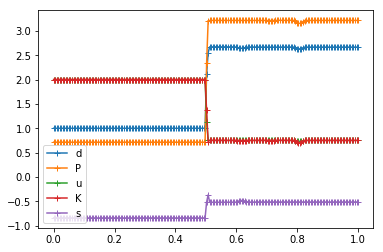

In [77]:
dtds=0.1
nstep=300
n=200
x,f=IC(n=n)
ds=x[1]-x[0]
dt=0.5*dtds*ds
for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f),dt=dt))))

for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

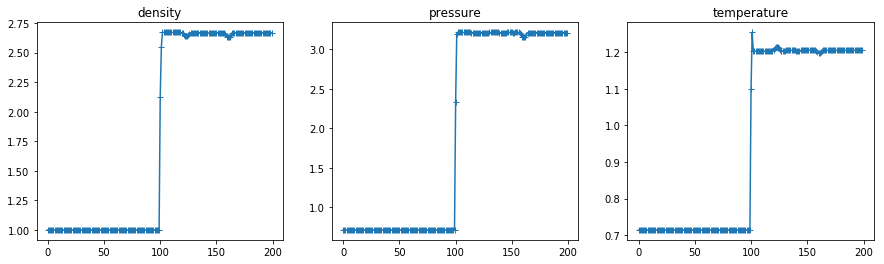

In [15]:
prim=ctoprim(f)
pl.figure(figsize=(15,4))
pl.subplot(1,3,1); pl.plot(prim[0],'-+'); pl.title('density')
pl.subplot(1,3,2); pl.plot(prim[1],'-+'); pl.title('pressure')
pl.subplot(1,3,3); pl.plot(prim[1]/prim[0],'-+'); pl.title('temperature');

### Stationary shock test

Show initial conditions

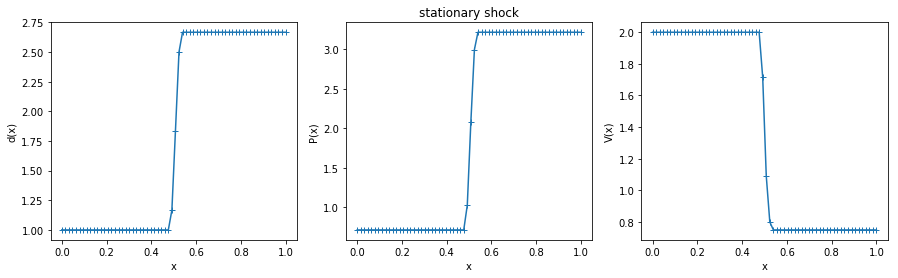

In [16]:
gamma=1.4
x,f=IC('stationary_shock',gamma=gamma)
pl.figure(figsize=(15,4))
pl.subplot(1,3,1); pl.plot(x,f[0],'-+');
pl.xlabel('x'); pl.ylabel('d(x)')
P=(gamma-1)*(f[1]-0.5*f[2]**2/f[0])
pl.subplot(1,3,2); pl.plot(x,P,'-+');
pl.xlabel('x'); pl.ylabel('P(x)'); pl.title('stationary shock');
pl.subplot(1,3,3); pl.plot(x,f[2]/f[0],'-+');
pl.xlabel('x'); pl.ylabel('V(x)');

Run the stationary shock:

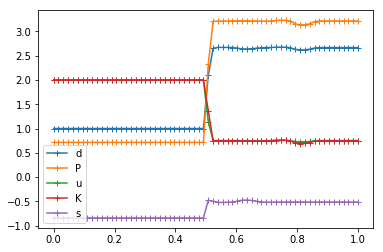

In [78]:
dtds=0.1
nstep=100
gamma=1.4
x,f=IC('stationary_shock',gamma=gamma)
ds=x[1]-x[0]
dt=dtds*ds

for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f),dt=dt))))

for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

So, a small adjustment happens immediately after launch, and to get a good initial condition for tests that perturbuation should be allowed to propagate out

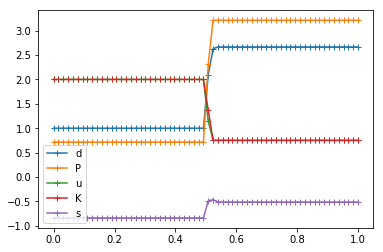

In [79]:
dtds=0.1
nstep=1000
gamma=1.4
n=64
x,f=IC('stationary_shock',gamma=gamma,n=n)

for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f),dt=dt))))
f0=np.copy(f)

for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

In [19]:
f0=np.copy(f)

In [20]:
f[:,0],f[:,-1]

(array([ 1.        ,  3.78571429,  2.        ,  2.        , -0.84118059]),
 array([ 2.66666667,  8.78571429,  2.        ,  0.75      , -1.37037196]))

### Local diagnostics

In [21]:
diag={}
pred=predict(ctoprim(f))
flux=hllc(pred,diag=diag)
diag.keys()

dict_keys(['case', 'SL', 'SR', 'ro', 'uo', 'Po', 'eo'])

64 32


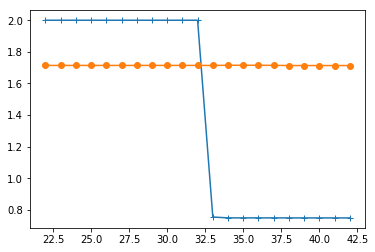

In [22]:
m=n//2
print(n,m)
w=21
ii=m-w//2+np.arange(w)
pl.plot(ii,np.array(diag['uo'])[ii],'-+');
pl.plot(ii,flux[2,ii]-3,'-o');

## Entropy based solver

We can keep the state vector, and only make alternative procedures:

In [80]:
def ctoprimS(f,gamma=1.4):
    """ This version uses f[0,2,4]as input, sets f[1,3] and returns a set of
        primitive variables
    """    
    m,n=f.shape
    d=f[0]
    p=f[2]
    S=f[4]
    s=S/d
    u=p/d
    P=d**gamma*np.exp((gamma-1)*s)
    K=0.5*d*u**2
    E=P/(gamma-1)+K
    f[1]=E
    f[3]=K
    return np.array((d,P,u,K,s))

Check that ``ctoprim()`` and ``ctoprimS()`` give consistent results

In [81]:
f[:]=f0[:]
ctoprim(f)
print(f[:,32])
ctoprimS(f)
print(f[:,32])

[ 2.09972595  7.17391064  2.39405173  1.36481708 -1.02569384]
[ 2.09972595  7.17391064  2.39405173  1.36481708 -1.02569384]


In [82]:
prim=ctoprimS(f)
pred=predict(prim,dt=dt)
flux=hllc(pred)
divf=div(flux)
df=dtds*BCs(divf)

In [83]:
prim[:,0],prim[:,-1]

(array([ 1.        ,  0.71428571,  2.        ,  2.        , -0.84118059]),
 array([ 2.66666667,  3.21428571,  0.75      ,  0.75      , -0.51388949]))

In [84]:
flux[:,0],flux[:,-1]

(array([ 2.        ,  9.        ,  4.71428571,  4.        , -1.68236118]),
 array([ 2.00003561,  8.99718298,  4.71360518,  0.56231588, -1.02982762]))

As a result of the calls to ``hllc()`` and ``divflux()``, the entropy state is updated with the divergence of an entropy flux that is the same as in the total energy case, and which thus is missing the contribution from the kinetic energy dissipation.  The effect of the kinetic energy dissipation is included in the Riemann solver, which thus in the limit of excellent resolution produces the correct entropy flux, but that flux alone is not sufficient to give the correct state after one timestep

## Single timestep test
We now have a state ``f`` that is stationary in HLLC.  We can save the state, and take one special step:

In [85]:
f[:]=f0[:]
prim=ctoprim(f)
pred=predict(prim,dt=dt)
flux=hllc(pred)
divf=div(flux)
df=dtds*BCs(divf)
fE=f-df

In [86]:
f[:]=f0[:]
prim=ctoprim(f)
primS=ctoprimS(f)
predS=predict(primS,dt=dt)
fluxS=hllc(predS)
divfS=div(fluxS)
dfS=dtds*BCs(divfS)
fS=f-dfS

In [87]:
print(prim[:,32])
print(primS[:,32])

[ 2.09972595  2.32363742  1.14017343  1.36481708 -0.48848939]
[ 2.09972595  2.32363742  1.14017343  1.36481708 -0.48848939]


In [88]:
print(pred[0][:,32])
print(predS[0][:,32])

[ 1.          0.71428571  2.          2.         -0.84118059]
[ 1.          0.71428571  2.          2.         -0.84118059]


In [89]:
print(flux[:,32])
print(fluxS[:,32])

[ 2.          9.          4.71428571  4.         -1.68236118]
[ 2.          9.          4.71428571  4.         -1.68236118]


In [90]:
print(fE[:,32])
print(fS[:,32])

[ 2.0997518   7.17399624  2.39408408  1.70774837 -1.09462805]
[ 2.0997518   7.17399624  2.39408408  1.70774837 -1.09462805]


(29, 35)

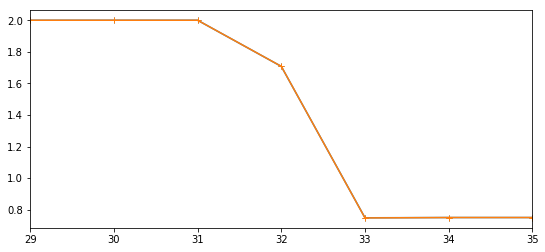

In [91]:
f=np.copy(f0)
for i in range(10):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

pl.figure(figsize=(9,4))
i=3
pl.plot(f0[i],'-+')
pl.plot(f[i],'-+')
pl.xlim(29,35)

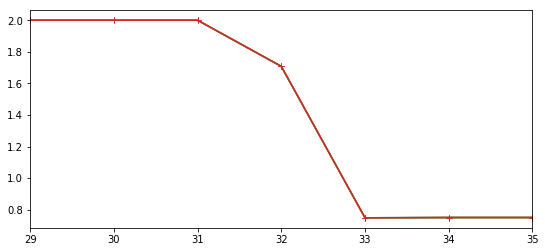

In [92]:
f=np.copy(f0)
nstep=1
for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprimS(f)))))

pl.figure(figsize=(9,4))
i=3
pl.plot(f0[i],'-+')
pl.plot(f[i],'-+')
pl.plot(fS[i],'-+')
pl.plot(fE[i],'-+')
pl.xlim(29,35);

Since the results are identical, we can in principle continue running with ``ctoprimS()``, but in practice the results start to deviate after a few dozen time steps>

[ 2.0063163   6.69823429  2.39426759  1.42861754 -1.08410384]
[ 2.09972595  7.17391064  2.39405173  1.70772834 -1.09458045]


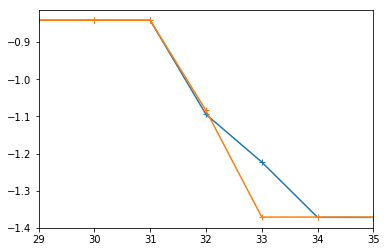

In [93]:
x,f=IC('stationary_shock',gamma=gamma,n=n)

for i in range(1000):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))
f0=np.copy(f)
for i in range(1000):
    f -= dtds*BCs(div(hllc(predict(ctoprimS(f)))))
    prim=ctoprimS(f)
    f[4] -= dtds*df[3]*prim[0]/prim[1]*2
i=4
pl.plot(f0[i],'-+')
pl.plot(f[i],'-+')
pl.xlim(29,35);
print(f[:,32])
print(f0[:,32])

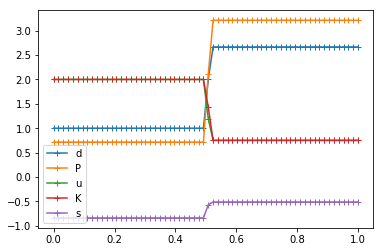

In [94]:
for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

In [76]:
print(df[3,30:35])

[ 0.00000000e+00 -1.77635684e-16 -3.42931290e-01 -7.86362188e-04
  2.10129118e-06]


In [38]:
df[3,30:35]

array([ 0.00000000e+00, -1.77635684e-16, -3.42931290e-01, -7.86362188e-04,
        2.10129118e-06])

Blank lines to avoid graphics moving out of focus

In [40]:
for i in range(30): print('')